<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

### Procesamiento de Lenguaje Natural I — CEIA FIUBA
# **Desafío 3 — Modelo de lenguaje con tokenización por caracteres**

**Alumno:** Jaime Ricardo Pinzon Aparicio (jaripia64@gmail.com) · Cohorte 26Co2026 (a264b26)

**Corpus propio:** *Don Quijote de la Mancha* (Miguel de Cervantes), texto plano del Proyecto
Gutenberg (eBook #2000).

**Contenido:**
1. Descarga, limpieza y análisis del corpus; vocabulario de caracteres.
2. Estructuración del dataset *many-to-many* (contexto 100), separación train/validación, con
   **corrección documentada de dos problemas de la plantilla** (ventanas de validación y padding
   en la perplejidad).
3. Tres arquitecturas recurrentes con el mismo presupuesto de unidades: **SimpleRNN, LSTM y
   GRU**, entrenadas con rmsprop y comparadas por **perplejidad en validación** (callback con
   early stopping), más una **SimpleRNN de 380 unidades como control de capacidad** (mismo orden
   de parámetros que las celdas con compuertas).
4. Generación de secuencias con **greedy search** y **beam search determinístico y
   estocástico**, estudiando el **efecto de la temperatura**, con métricas cuantitativas comparadas contra
   **muestreo ancestral puro** y contra **texto real** de validación.

> Cada experimento está acompañado de su interpretación, cada decisión está justificada en el
> texto, y **toda cifra citada en los análisis proviene de un output visible del notebook** (salvo la
> mención explícita a corridas exploratorias previas en la sección de entrenamiento).

⚙️ **Nota de entorno:** el notebook corre sobre **Keras 3 con backend PyTorch** (GPU local
NVIDIA GTX 1050). La API de Keras es la misma que la vista en clase con TensorFlow; las dos
únicas adaptaciones necesarias (capa de one-hot y guardado del mejor modelo) están señaladas y
justificadas donde aparecen.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"  # debe definirse ANTES de importar keras

import re
import io
import time
import random
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras import layers
from keras.models import Sequential
from keras.utils import pad_sequences
import torch

SEED = 42
keras.utils.set_random_seed(SEED)  # fija random, numpy y torch

print("keras:", keras.__version__, "| backend:", keras.backend.backend())
print("GPU disponible:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

keras: 3.1.1 | backend: torch
GPU disponible: True | NVIDIA GeForce GTX 1050


### Datos: *Don Quijote de la Mancha*

**Por qué este corpus:** un modelo de lenguaje por caracteres necesita un texto largo, de estilo
homogéneo y con ortografía consistente. El Quijote (eBook #2000 de Gutenberg, ~2,1 MB) cumple
las tres cosas y tiene una prosa tan reconocible que permite evaluar *a ojo* si las secuencias
generadas "suenan" al corpus — un complemento cualitativo de la perplejidad. Además el español
agrega un detalle interesante a nivel caracter: tildes, «ñ» y signos de apertura (¿¡) que el
modelo debe aprender a usar.

La descarga intenta primero el sitio principal de Gutenberg y, si está saturado (HTTP 503, algo
frecuente), cae a un mirror oficial. El texto se cachea en `quijote.txt`.

In [2]:
URLS_QUIJOTE = [
    "https://www.gutenberg.org/files/2000/2000-0.txt",
    "http://aleph.gutenberg.org/2/0/0/2000/2000-0.txt",  # mirror oficial (pglaf)
]

if os.path.exists("quijote.txt"):
    with open("quijote.txt", encoding="utf-8") as fp:
        raw = fp.read()
    print("Usando caché local quijote.txt")
else:
    raw = None
    for url in URLS_QUIJOTE:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            raw = urllib.request.urlopen(req, timeout=60).read().decode("utf-8")
            print("Descargado de:", url)
            break
        except Exception as e:
            print("Fallo", url, "->", e)
    assert raw is not None, "No se pudo descargar el corpus"
    with open("quijote.txt", "w", encoding="utf-8") as fp:
        fp.write(raw)

print(f"Tamaño crudo: {len(raw):,} caracteres")

Usando caché local quijote.txt
Tamaño crudo: 2,110,809 caracteres


### Limpieza y tamaño del corpus de trabajo

- Se recorta el **encabezado y pie legales de Gutenberg** (delimitados por `*** START/END OF ...`).
- Se saltea el **aparato editorial** del comienzo (tasa, privilegio, prólogo, poemas preliminares
  y, sobre todo, el **índice de capítulos**: una lista de títulos del tipo "de lo que le sucedió a
  don quijote con..."). Son 38.755 caracteres (salida de abajo) con un registro muy distinto al de
  la novela; dejarlos habría enseñado al modelo a generar títulos de capítulo. El corpus empieza
  en el primer "capítulo primero".
- Se pasa todo a **minúsculas** (igual que el material de clase): duplicar cada letra en versión
  mayúscula/minúscula duplicaría el vocabulario sin aportar al objetivo del desafío.
- Los **saltos de línea y espacios múltiples se colapsan a un espacio**: en el archivo de
  Gutenberg el corte de línea es tipográfico (ancho fijo), no lingüístico.
- La diéresis (ü, ï) se **normaliza** a la vocal simple en lugar de eliminarse: "vergüenza" queda
  "verguenza" (legible) y no "vergenza".
- Nos quedamos con los primeros **400.000 caracteres** del texto limpio. La decisión es de
  **presupuesto de cómputo**: el dataset *many-to-many* multiplica cada caracter por el tamaño
  del contexto, y entrenamos **cuatro** redes en una GPU local de 2 GB. Con 400k caracteres el
  entrenamiento de las cuatro redes suma ~2 h 12 min (tabla de comparación: épocas × s/época; la
  LSTM sola, ~64 min) y quedan 89.933 secuencias de
  entrenamiento de 100 caracteres (medido más abajo), suficiente para comparar arquitecturas, que
  es el objetivo de la consigna.

In [3]:
inicio = raw.find("*** START OF")
inicio = raw.find("\n", inicio) + 1
fin = raw.find("*** END OF")
texto = raw[inicio:fin].lower()
texto = re.sub(r"\s+", " ", texto).strip()
print(f"Texto limpio completo: {len(texto):,} caracteres")

# El archivo arranca con aparato editorial (tasa, privilegio, prólogo, poemas preliminares y el
# ÍNDICE de capítulos: una lista de títulos del tipo "de lo que le sucedió a don quijote con...").
# Lo salteamos: el corpus empieza en el primer "capítulo primero" (inicio de la novela).
comienzo = texto.find("capítulo primero")
print(f"Se saltean {comienzo:,} caracteres de aparato editorial e índice")
texto = texto[comienzo:]

# Diéresis: 'ü'/'ï' son poco frecuentes; en lugar de BORRARLAS (lo que deformaría "vergüenza" en
# "vergenza") las normalizamos a la vocal simple ("verguenza"), que conserva la palabra legible.
texto = texto.replace("ü", "u").replace("ï", "i")

N_CHARS = 400_000
texto = texto[:N_CHARS]
print(f"Corpus de trabajo:     {len(texto):,} caracteres")
print("\nMuestra:", repr(texto[:300]))


Texto limpio completo: 2,104,963 caracteres
Se saltean 38,755 caracteres de aparato editorial e índice
Corpus de trabajo:     400,000 caracteres

Muestra: 'capítulo primero. que trata de la condición y ejercicio del famoso hidalgo don quijote de la mancha en un lugar de la mancha, de cuyo nombre no quiero acordarme, no ha mucho tiempo que vivía un hidalgo de los de lanza en astillero, adarga antigua, rocín flaco y galgo corredor. una olla de algo más v'


### Vocabulario de caracteres

El vocabulario es el conjunto de caracteres únicos del texto. Antes de congelarlo miramos la
**frecuencia** de cada caracter: los muy raros (números sueltos, puntuación exótica del aparato
editorial) obligan al modelo a reservar una fila de la softmax para algo que casi nunca ve.
**Decisión:** los caracteres con menos de 50 apariciones en 400k (< 0,0125%) se eliminan del
texto. Es una pérdida de información despreciable que reduce el vocabulario y estabiliza la
estimación de probabilidades. En la salida de abajo: se eliminan 8 caracteres (la «x», comillas,
paréntesis y guion, todos con menos de 50 apariciones) y el vocabulario final queda en **39
caracteres**. Los signos de apertura (¿ ¡) y la «ñ» superan el umbral y se conservan.
**Costo reconocido:** la «x» es una letra, no un símbolo: al borrarla, sus 46 apariciones deforman
las palabras que la contienen ("experiencia" → "eperiencia", "extraordinario" → "etraordinario"). Afecta a ~0,01% de los caracteres y la
deformación es la misma en entrenamiento, validación y en el vocabulario de palabras usado por las
métricas, así que no sesga las comparaciones; pero habría sido más prolijo conservarla (o
mapearla a "j"/"cs"), y es lo primero que cambiaríamos.

In [4]:
freqs = Counter(texto)
tabla_freq = pd.DataFrame(sorted(freqs.items(), key=lambda kv: kv[1]),
                          columns=["caracter", "frecuencia"])
print("Caracteres menos frecuentes:")
print(tabla_freq.head(15).to_string(index=False))

MIN_FREQ = 50
raros = [c for c, f in freqs.items() if f < MIN_FREQ]
print(f"\nSe eliminan {len(raros)} caracteres raros: {raros}")
texto = "".join(c for c in texto if c not in raros)

chars_vocab = sorted(set(texto))
vocab_size = len(chars_vocab)
char2idx = {c: i for i, c in enumerate(chars_vocab)}
idx2char = {i: c for c, i in char2idx.items()}
print(f"\nVocabulario final: {vocab_size} caracteres")
print("".join(chars_vocab))

tokenized_text = [char2idx[c] for c in texto]

Caracteres menos frecuentes:
caracter  frecuencia
       -           7
       (          16
       )          16
       «          17
       "          20
       »          27
       '          40
       x          46
       ¡          95
       !          95
       ¿         164
       ?         164
       ú         243
       :         313
       ñ         720

Se eliminan 8 caracteres raros: ['x', "'", '«', '»', '(', ')', '-', '"']

Vocabulario final: 39 caracteres
 !,.:;?abcdefghijlmnopqrstuvyz¡¿áéíñóú—


### Estructuración del dataset (*many-to-many*)

Cada ejemplo es una ventana de `max_context_size = 100` caracteres; el *target* es la misma
ventana desplazada un caracter: la red aprende a predecir el **próximo caracter en cada
posición**, y así cada ventana propaga 100 señales de gradiente (ventaja del planteo
*many-to-many* explicada en el material de clase).

Dos diferencias deliberadas respecto de la plantilla, ambas documentadas:

1. ⚠️ **Bug corregido en las ventanas de validación.** La plantilla construye
   `val_text[init*mcs : init*(mcs+1)]`, que produce ventanas de largo `init*(mcs+1) − init*mcs = init`, es decir de 0, 1, 2, …,
   `num_val`−1 caracteres. Con nuestro corpus, `num_val` sería ≈ 400 (10% de 400k / 100). Las
   primeras ventanas son casi vacías (y el padding con el índice 0 las contamina), mientras que la
   mayoría supera los 100 caracteres y `pad_sequences(maxlen=100)` las trunca. La validación
   queda dominada por ventanas largas evaluadas sobre cientos de prefijos truncados, en lugar de
   las ventanas de 100 que se pretendían. El corte correcto es `[init*mcs : (init+1)*mcs]`. Acá armamos las ventanas de
   validación en forma **contigua y no solapada** (y el split train/val es un corte temporal del
   texto, sin mezcla).
2. **Stride en las ventanas de entrenamiento.** La plantilla usa stride 1 (cada caracter inicia
   una ventana): ventanas consecutivas comparten 99 de 100 caracteres, una redundancia enorme.
   Usamos `STRIDE = 4`: cada caracter sigue apareciendo en ~25 ventanas por época (en posiciones
   distintas del contexto), con un costo por época 4 veces menor. Es la palanca que nos permite
   comparar tres arquitecturas con el mismo presupuesto.

In [5]:
max_context_size = 100
STRIDE = 4
P_VAL = 0.1

# corte temporal: el último 10% del texto es validación
n_val_chars = int(len(tokenized_text) * P_VAL)
train_text = tokenized_text[:-n_val_chars]
val_text = tokenized_text[-n_val_chars:]

def ventanas(texto_tok, stride, largo):
    # ventanas de (largo+1): los primeros `largo` tokens son X, los últimos `largo` son y
    return np.array([texto_tok[i:i + largo + 1]
                     for i in range(0, len(texto_tok) - largo - 1, stride)], dtype=np.int32)

W_train = ventanas(train_text, STRIDE, max_context_size)
W_val = ventanas(val_text, max_context_size + 1, max_context_size)  # no solapadas

X, y = W_train[:, :-1], W_train[:, 1:]
X_val, y_val = W_val[:, :-1], W_val[:, 1:]

print(f"Caracteres train: {len(train_text):,} | validación: {len(val_text):,}")
print(f"X: {X.shape} | y: {y.shape}")
print(f"X_val: {X_val.shape} | y_val: {y_val.shape}")

# sanity check: el target es la entrada corrida un caracter
dec = lambda seq: "".join(idx2char[i] for i in seq)
print("\nX[0][:60]:", dec(X[0][:60]))
print("y[0][:60]:", dec(y[0][:60]))

Caracteres train: 359,830 | validación: 39,981
X: (89933, 100) | y: (89933, 100)
X_val: (395, 100) | y_val: (395, 100)

X[0][:60]: capítulo primero. que trata de la condición y ejercicio del 
y[0][:60]: apítulo primero. que trata de la condición y ejercicio del f


# Modelos propuestos

Comparamos **tres celdas recurrentes con el mismo presupuesto de unidades** (200 unidades, mismo
optimizador, mismos datos): **SimpleRNN** (celda de Elman, la de la plantilla), **LSTM** y **GRU**. La teoría
de la clase 3 predice el resultado: con contexto de 100 pasos, la SimpleRNN debería sufrir
*vanishing gradients* y quedarse con dependencias cortas, mientras que las celdas con compuertas
pueden retener dependencias largas. Este desafío lo verifica con la métrica correcta para un
modelo de lenguaje: la **perplejidad en validación**. Como 200 unidades de LSTM o GRU tienen 3 a 4
veces más parámetros que 200 de SimpleRNN, agregamos un **control de capacidad**: una SimpleRNN de
380 unidades (174k parámetros, del orden de los 152k de la GRU). Si la ventaja de las compuertas
fuera solo de capacidad, ese control debería alcanzarlas.

Decisiones:

- **Sin capa de embedding** (como la plantilla): la entrada se transforma a one-hot. Con un
  vocabulario de ~40 caracteres, un embedding denso aporta poco y agrega parámetros.
  ⚙️ *Adaptación Keras 3:* la combinación `TimeDistributed(CategoryEncoding)` de la plantilla
  produce en Keras 3 un tensor 4D `(batch, t, 1, vocab)` que rompe la capa recurrente
  (`expected ndim=3, found ndim=4`); la reemplazamos por una capa `Lambda` con
  `keras.ops.one_hot`, que es exactamente la misma transformación.
- **`dropout=0.1`** como la plantilla. Omitimos `recurrent_dropout` porque en el backend torch
  obliga a abandonar el kernel recurrente optimizado (el entrenamiento se vuelve varias veces
  más lento) y el sobreajuste observado queda acotado por el early stopping: las brechas apreciables
  entre entrenamiento y validación aparecen en la GRU y en la SimpleRNN de 380 unidades, y en
  ambas el entrenamiento se corta pocas épocas después (ver la figura y la tabla de abajo).
- **Optimizador `rmsprop`**, el recomendado por la consigna para buena convergencia.
- **`sparse_categorical_crossentropy`**: los targets son índices enteros, no one-hot.

In [6]:
def crear_modelo(celda, unidades=200):
    capa = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[celda]
    model = Sequential([
        layers.Input(shape=(None,), dtype="int32"),
        layers.Lambda(lambda t: keras.ops.one_hot(keras.ops.cast(t, "int32"), vocab_size),
                      output_shape=(None, vocab_size)),
        capa(unidades, return_sequences=True, dropout=0.1),
        layers.Dense(vocab_size, activation="softmax"),
    ], name=f"lm_{celda}")
    model.compile(loss="sparse_categorical_crossentropy", optimizer="rmsprop")
    return model

for celda in ["SimpleRNN", "LSTM", "GRU"]:
    crear_modelo(celda).summary()

Model: "lm_SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, None, 39)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, None, 200)      │        48,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 39)       │         7,839 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,839 (218.12 KB)

 Trainable params: 55,839 (218.12 KB)

 Non-trainable params: 0 (0.00 B)

Model: "lm_LSTM"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_2 (Lambda)               │ (None, None, 39)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, None, 200)      │       144,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, None, 39)       │         7,839 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,439 (595.46 KB)

 Trainable params: 152,439 (595.46 KB)

 Non-trainable params: 0 (0.00 B)

### Perplejidad en validación: callback con early stopping

La perplejidad (promedio geométrico inverso de las probabilidades asignadas al caracter
verdadero, calculada con logaritmos) se mide al final de cada época sobre las ventanas de
validación; si no mejora durante `patience=3` épocas, se detiene el entrenamiento y se conservan
los **pesos del mejor punto**.

⚠️ **Segunda corrección sobre la plantilla, justificada:** el callback original construye las
~100 subsecuencias-prefijo de cada ventana de validación, les aplica `pad_sequences(padding=
'pre')` y predice cada una por separado. Eso tiene dos problemas: (a) el padding usa el índice
**0, que en nuestro vocabulario es un caracter real**, de modo que los prefijos cortos quedan
contaminados con contexto falso; y (b) cuesta O(L²) predicciones. Como la red es **causal** (la
salida en la posición *t* solo depende de las entradas ≤ *t*), una **única pasada** sobre la
ventana completa produce exactamente las mismas probabilidades que todos los prefijos sin
padding: el cálculo queda libre del sesgo del padding y 100 veces más barato.
*(Adaptación Keras 3: guardamos `save_weights` en lugar del modelo completo, porque la capa
`Lambda` no se serializa de forma segura.)*

In [7]:
class PplCallback(keras.callbacks.Callback):
    """Perplejidad sobre validación al final de cada época + early stopping.

    Una sola pasada teacher-forcing por ventana (red causal => equivalente a evaluar
    todos los prefijos, sin el sesgo del padding con el token 0).
    """

    def __init__(self, X_val, y_val, nombre, patience=3):
        super().__init__()
        self.X_val, self.y_val = X_val, y_val
        self.nombre = nombre
        self.patience = patience
        self.historia = []
        self.min_score = np.inf
        self.patience_counter = 0

    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.X_val, verbose=0, batch_size=256)
        # probabilidad asignada al caracter verdadero en cada posición de cada ventana
        probs = np.take_along_axis(pred, self.y_val[..., None], axis=-1)[..., 0]
        ppl_por_ventana = np.exp(-np.mean(np.log(probs + 1e-10), axis=1))
        score = float(np.mean(ppl_por_ventana))
        self.historia.append(score)
        print(f"  época {epoch + 1}: perplejidad val = {score:.2f}")

        if score < self.min_score:
            self.min_score = score
            self.model.save_weights(f"mejor_{self.nombre}.weights.h5")
            self.patience_counter = 0
        else:
            self.patience_counter += 1
            if self.patience_counter >= self.patience:
                print(f"  early stopping (sin mejora en {self.patience} épocas)")
                self.model.stop_training = True

### Entrenamiento de las tres arquitecturas (y el control de capacidad)

`batch_size=256` (el más grande que entra con holgura en los 2 GB de la GPU con secuencias de
100 × one-hot). Máximo **60 épocas**, con early stopping (`patience=3`) sobre la perplejidad de
validación. La intención es que **cada arquitectura entrene hasta converger** y la comparación no
favorezca a las que convergen más rápido; las tres de base y el control lo logran, la LSTM llega
al tope a una época de cumplir el criterio (ver abajo). El tope viene de corridas exploratorias anteriores (no incluidas en este notebook): con 18 y
luego con 40 épocas la LSTM, que es la que arranca más lento, todavía mejoraba al llegar al tope. 60 épocas es el
presupuesto disponible (~1 hora solo para la LSTM). Abajo se discute qué pasó con cada red
respecto de ese tope. Todas parten de la misma semilla (`keras.utils.set_random_seed`); con backend torch en GPU eso
no garantiza resultados bit a bit idénticos entre corridas (cuDNN no es determinista).

Usamos `patience=3` en lugar de los 5 de la plantilla, también por presupuesto. Es un criterio
algo agresivo con curvas de validación ruidosas (por ejemplo, la SimpleRNN-380 hace
4,87 → 5,00 → 4,92 → 4,88): una red podría cortarse antes de un último tramo de mejora. Lo tenemos en
cuenta al interpretar diferencias chicas.

In [8]:
EPOCHS = 60
BATCH = 256
resultados = {}


def entrenar(celda, unidades=200, nombre=None):
    """Entrena una arquitectura en las mismas condiciones y registra sus resultados."""
    nombre = nombre or celda
    print(f"=== {nombre} ===")
    keras.utils.set_random_seed(SEED)  # mismas condiciones iniciales para todas
    model = crear_modelo(celda, unidades)
    cb = PplCallback(X_val, y_val, nombre)
    t0 = time.time()
    hist = model.fit(X, y, epochs=EPOCHS, batch_size=BATCH, callbacks=[cb], verbose=2)
    seg_por_epoca = (time.time() - t0) / len(cb.historia)
    model.load_weights(f"mejor_{nombre}.weights.h5")  # nos quedamos con la mejor época
    resultados[nombre] = {
        "celda": celda,
        "unidades": unidades,
        "modelo": model,
        "historia": cb.historia,
        "mejor_ppl": cb.min_score,
        "params": model.count_params(),
        "seg_epoca": seg_por_epoca,
        "loss_train": hist.history["loss"],
    }
    print(f"{nombre}: mejor ppl = {cb.min_score:.2f} | {seg_por_epoca:.0f} s/época")


In [9]:
entrenar("SimpleRNN")

=== SimpleRNN ===
Epoch 1/60


  época 1: perplejidad val = 7.46
352/352 - 40s - 114ms/step - loss: 2.2803


Epoch 2/60


  época 2: perplejidad val = 6.66
352/352 - 40s - 112ms/step - loss: 1.9853


Epoch 3/60


  época 3: perplejidad val = 6.17
352/352 - 40s - 113ms/step - loss: 1.8900


... (55 outputs left out)

  época 31: perplejidad val = 4.49
352/352 - 39s - 112ms/step - loss: 1.4872


Epoch 32/60


  época 32: perplejidad val = 4.49
  early stopping (sin mejora en 3 épocas)
352/352 - 40s - 113ms/step - loss: 1.4850


SimpleRNN: mejor ppl = 4.48 | 40 s/época


In [10]:
entrenar("LSTM")

=== LSTM ===
Epoch 1/60


  época 1: perplejidad val = 9.65
352/352 - 64s - 183ms/step - loss: 2.6316


Epoch 2/60


  época 2: perplejidad val = 7.94
352/352 - 64s - 183ms/step - loss: 2.1884


Epoch 3/60


  época 3: perplejidad val = 7.18
352/352 - 65s - 185ms/step - loss: 2.0674


... (111 outputs left out)

  época 59: perplejidad val = 4.20
352/352 - 64s - 182ms/step - loss: 1.4108


Epoch 60/60


  época 60: perplejidad val = 4.16
352/352 - 64s - 181ms/step - loss: 1.4073


LSTM: mejor ppl = 4.15 | 64 s/época


In [11]:
entrenar("GRU")

=== GRU ===
Epoch 1/60


  época 1: perplejidad val = 8.07
352/352 - 88s - 250ms/step - loss: 2.4326


Epoch 2/60


  época 2: perplejidad val = 6.91
352/352 - 88s - 249ms/step - loss: 2.0559


Epoch 3/60


  época 3: perplejidad val = 6.20
352/352 - 87s - 248ms/step - loss: 1.9281


... (37 outputs left out)

  época 22: perplejidad val = 4.21
352/352 - 88s - 249ms/step - loss: 1.3595


Epoch 23/60


  época 23: perplejidad val = 4.18
  early stopping (sin mejora en 3 épocas)
352/352 - 87s - 248ms/step - loss: 1.3518


GRU: mejor ppl = 4.17 | 88 s/época


In [12]:
# Control de capacidad: una SimpleRNN con 380 unidades tiene ~174k parámetros, del orden de los
# 152k de la GRU de 200 unidades. Si iguala a la GRU, la ventaja de las compuertas era capacidad.
entrenar("SimpleRNN", unidades=380, nombre="SimpleRNN-380")

=== SimpleRNN-380 ===
Epoch 1/60


  época 1: perplejidad val = 7.44
352/352 - 39s - 111ms/step - loss: 2.2722


Epoch 2/60


  época 2: perplejidad val = 6.69
352/352 - 39s - 111ms/step - loss: 1.9693


Epoch 3/60


  época 3: perplejidad val = 6.18
352/352 - 39s - 112ms/step - loss: 1.8490


... (31 outputs left out)

  época 19: perplejidad val = 4.92
352/352 - 39s - 112ms/step - loss: 1.3922


Epoch 20/60


  época 20: perplejidad val = 4.88
  early stopping (sin mejora en 3 épocas)
352/352 - 39s - 112ms/step - loss: 1.3849


SimpleRNN-380: mejor ppl = 4.87 | 39 s/época


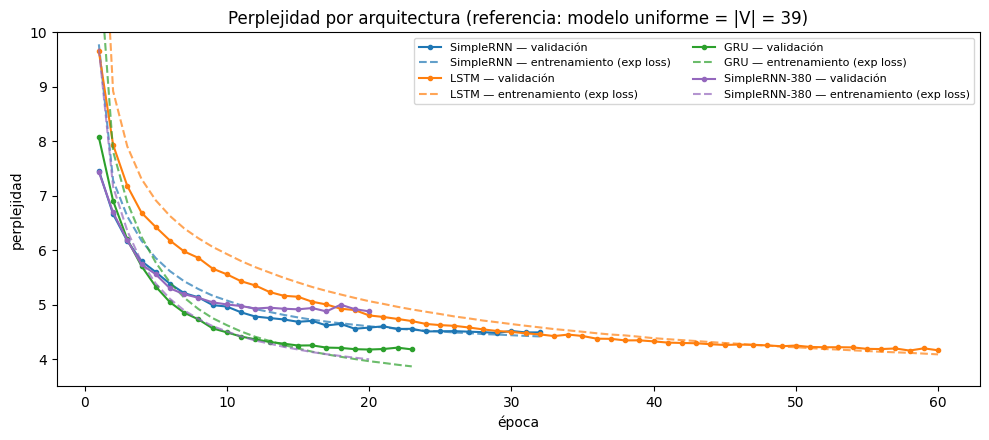

,unidades,mejor ppl (val),época del mejor,épocas corridas,ppl train última época,parámetros,s/época
SimpleRNN,200.0,4.48,29.0,32.0,4.41,55839.0,39.6
LSTM,200.0,4.15,58.0,60.0,4.08,199839.0,64.1
GRU,200.0,4.17,20.0,23.0,3.86,152439.0,87.8
SimpleRNN-380,380.0,4.87,17.0,20.0,3.99,174459.0,39.3


In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colores = {"SimpleRNN": "tab:blue", "LSTM": "tab:orange", "GRU": "tab:green", "SimpleRNN-380": "tab:purple"}
for celda, r in resultados.items():
    ep = range(1, len(r["historia"]) + 1)
    ax.plot(ep, r["historia"], marker="o", ms=3, color=colores[celda], label=f"{celda} — validación")
    # perplejidad de entrenamiento = exp(cross-entropy media de la época; incluye dropout)
    ax.plot(ep, np.exp(r["loss_train"]), ls="--", color=colores[celda], alpha=0.7,
            label=f"{celda} — entrenamiento (exp loss)")
ax.set_xlabel("época"); ax.set_ylabel("perplejidad")
ax.set_ylim(3.5, 10)  # recortado para ver las diferencias finales (la 1.ª época de algunas queda afuera)
ax.set_title(f"Perplejidad por arquitectura (referencia: modelo uniforme = |V| = {vocab_size})")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

tabla = pd.DataFrame({c: {"unidades": r["unidades"],
                          "mejor ppl (val)": round(r["mejor_ppl"], 2),
                          "época del mejor": int(np.argmin(r["historia"]) + 1),
                          "épocas corridas": len(r["historia"]),
                          "ppl train última época": round(float(np.exp(r["loss_train"][-1])), 2),
                          "parámetros": r["params"],
                          "s/época": round(r["seg_epoca"], 1)}
                      for c, r in resultados.items()}).T
tabla


**Interpretación de la comparación** (tabla y figura anteriores):

- **Todas las redes aprendieron el idioma a nivel caracter.** Sus perplejidades de validación
  (4,15 a 4,87) están 8 a 9,4 veces por debajo de la de un modelo uniforme (|V| = 39). Una
  perplejidad de ~4,2 significa que, en promedio, el modelo duda entre unos 4 caracteres
  igualmente probables, frente a los 39 posibles.
- **Ranking: LSTM (4,15) ≈ GRU (4,17) < SimpleRNN (4,48) < SimpleRNN-380 (4,87).** Las dos celdas
  con compuertas superan a la celda de Elman, como predice la teoría de la clase 3. La diferencia
  es **moderada**: −7% de perplejidad entre la LSTM y la SimpleRNN de 200 unidades. Una
  explicación plausible es que, a nivel caracter, gran parte de lo predecible es local: completar
  una palabra o elegir la terminación correcta depende de los últimos 5 a 10 caracteres, algo que
  la SimpleRNN también resuelve. Entre LSTM y GRU, en cambio, la diferencia (0,02) es
  **despreciable**: con una sola semilla por red no podemos decir cuál es mejor; las tratamos como
  empatadas.
- **Control de capacidad: más parámetros no alcanzan.** La SimpleRNN de 380 unidades tiene 174.459
  parámetros (más que los 152.439 de la GRU) y aun así es la **peor** de las cuatro: 4,87, contra
  4,48 de la SimpleRNN chica. La figura muestra por qué: su perplejidad de entrenamiento sigue
  bajando mientras la de validación se estanca cerca de 4,9 desde la época ~11. En su mejor época
  (la 17) la brecha entre entrenamiento y validación es la más grande de todas (0,78, ver el punto
  de sobreajuste): la capacidad extra se va en **memorizar** el texto de entrenamiento, no en
  generalizar. Entonces la ventaja de LSTM y GRU **no se explica por su cantidad de parámetros**:
  a igual capacidad, la celda sin compuertas generaliza mucho peor. Es consistente con la
  explicación de la teoría (las compuertas regulan qué información se conserva, lo que facilita el
  entrenamiento), aunque ningún experimento mide directamente dependencias largas, así que esa
  explicación sigue siendo compatible con los datos y no una prueba. **Salvedad:** usamos los
  mismos hiperparámetros (tasa de aprendizaje, `dropout=0.1`) para las cuatro; una SimpleRNN grande
  con más regularización podría rendir mejor, y eso no lo exploramos.
- **Convergencia y presupuesto.** La SimpleRNN, la GRU y la SimpleRNN-380 se detuvieron por early
  stopping (mejor época 29, 20 y 17, de 32, 23 y 20 corridas). La **LSTM llegó al tope de 60
  épocas** sin cumplir el criterio: su mejor época es la 58 (4,15) y las dos siguientes no la
  mejoraron (4,20 y 4,16), a una época de disparar el early stopping. Entre la época 54 y la 58 bajó
  apenas de 4,21 a 4,15: está **prácticamente convergida**, aunque no podemos descartar una mejora
  marginal con más épocas. La LSTM es la que arranca más lento: es peor que la SimpleRNN época a
  época hasta la 29 (4,51 contra 4,48) y recién desde la 30 la supera. No lo atribuimos a su
  cantidad de parámetros: la GRU, con 2,7 veces los de la SimpleRNN, es la que más rápido baja a
  partir de la época 4. No
  investigamos la causa (inicialización, dinámica de las compuertas con rmsprop).
- **Costo.** Por época: 40 s (SimpleRNN), 64 s (LSTM), 88 s (GRU) y 39 s (SimpleRNN-380). En total:
  ~21, ~64, ~34 y ~13 minutos. Para la misma **perplejidad objetivo** la GRU es mucho más rápida:
  alcanza 4,17 en la época 20 (~29 min = 20 × 88 s), mientras que la LSTM recién baja de 4,18 en la
  época 58 (~62 min = 58 × 64 s). En tiempo total de corrida, la GRU usó ~34 min contra ~64 de la
  LSTM (53%). Que la GRU sea más lenta por época que la LSTM a pesar
  de tener menos parámetros es probablemente un efecto de la implementación del backend torch, que
  no verificamos.
- **Sobreajuste**, medido en la **mejor época** de cada red (la que se conserva), comparando la
  perplejidad de entrenamiento exp(loss), con la loss visible en el log de cada época, contra la
  de validación:

  | red | mejor época | ppl train = exp(loss) | ppl val | brecha |
  |---|---|---|---|---|
  | SimpleRNN | 29 | 4,45 | 4,48 | 0,03 |
  | LSTM | 58 | 4,11 | 4,15 | 0,04 |
  | GRU | 20 | 3,96 | 4,17 | 0,21 |
  | SimpleRNN-380 | 17 | 4,09 | 4,87 | 0,78 |

  La SimpleRNN y la LSTM no sobreajustan. La **GRU** abre una brecha moderada (0,21), que sigue
  creciendo en las épocas siguientes (la tabla de comparación muestra 3,86 de entrenamiento en la
  última época) mientras la validación se estanca: el early stopping corta ahí. La
  **SimpleRNN-380** es el caso claro de sobreajuste, discutido arriba. (La columna "ppl train última
  época" de la tabla de comparación es de la **última** época corrida, no de la mejor, y por eso
  exagera las brechas.)
- **Nota sobre las escalas de la figura.** La curva de validación es el promedio de las
  perplejidades de cada ventana (el callback de la cátedra, con nuestra corrección). Por la
  desigualdad de Jensen, ese promedio es ≥ exp(NLL media): más abajo, la celda de generación mide
  sobre las mismas ventanas una perplejidad "de corpus" (exp de la NLL media de todos los
  caracteres) de **4,06**, contra 4,15 del promedio por ventana. Además, la de entrenamiento es
  exp(loss media) y se calcula con dropout activo, y es el **promedio a lo largo de la época**, con
  pesos que van mejorando, mientras que la validación se mide con los pesos del **final** de la
  época: este último efecto domina en las primeras épocas y explica que la curva de entrenamiento
  de la LSTM quede por encima de la de validación tanto tiempo. Por todo esto las dos curvas no
  están exactamente en la misma escala, y las brechas chicas (como la de la SimpleRNN) no deben
  sobreinterpretarse. Las de la GRU (0,21) y la SimpleRNN-380 (0,78) son lo bastante grandes para
  leerse como sobreajuste. El eje y está recortado en 10 para que se vean las diferencias finales,
  así que queda fuera de cuadro la primera época de entrenamiento de algunas redes; y la curva
  punteada de la SimpleRNN-380 queda casi superpuesta a la de la GRU (tabla de arriba para los
  valores).
- **Elección del modelo para generar: LSTM**, por la regla fijada de antemano (la de menor
  perplejidad de validación). Dado el empate con la GRU, la generación sería esencialmente la misma
  con cualquiera de las dos. **Limitación:** cada red se entrenó con **una sola semilla**, así que
  no medimos la variabilidad entre corridas. La diferencia LSTM–GRU queda dentro de esa
  incertidumbre; la ventaja de ambas sobre las dos SimpleRNN (0,3 a 0,7 de perplejidad) es más
  clara. Además, el early stopping, la elección del modelo y la perplejidad reportada usan el
  **mismo** conjunto de validación (no separamos un test), así que las perplejidades son
  levemente optimistas; como las cuatro redes tienen el mismo sesgo, la comparación entre ellas
  no se ve afectada.

# Generación de secuencias

Recuperamos los **pesos del mejor punto de validación** del modelo ganador y generamos texto a
partir de secuencias de contexto ("semillas") tomadas del universo del corpus.

⚠️ A diferencia de la plantilla, **no usamos `pad_sequences` en la generación**: la red acepta
secuencias de largo variable, y rellenar con el índice 0 (que es un caracter real de nuestro
vocabulario) contaminaría el contexto — el mismo problema señalado en el callback. Si el
contexto supera los 100 caracteres, nos quedamos con los últimos 100 (el largo con el que la red
fue entrenada).

In [14]:
mejor_celda = min(resultados, key=lambda c: resultados[c]["mejor_ppl"])
print("Mejor arquitectura por perplejidad de validación:", mejor_celda)

model = crear_modelo(resultados[mejor_celda]["celda"], resultados[mejor_celda]["unidades"])
# save_weights también guarda el estado del optimizador; para inferencia no lo necesitamos y
# Keras avisa que no lo restaura (el modelo nuevo aún no tiene slots de rmsprop). Es inocuo:
# los pesos de la red sí se cargan, como verifica la perplejidad recalculada abajo.
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")
    model.load_weights(f"mejor_{mejor_celda}.weights.h5")

# verificación del load: la ppl recalculada debe coincidir con la mejor registrada
pred = model.predict(X_val, verbose=0, batch_size=256)
probs = np.take_along_axis(pred, y_val[..., None], axis=-1)[..., 0]
ppl_final = float(np.mean(np.exp(-np.mean(np.log(probs + 1e-10), axis=1))))
print(f"Perplejidad en validación del modelo cargado: {ppl_final:.2f} "
      f"(registrada durante el entrenamiento: {resultados[mejor_celda]['mejor_ppl']:.2f})")
# misma información agregada sobre TODOS los caracteres (sin promediar por ventana):
logp_real = float(np.mean(np.log(probs + 1e-10)))
print(f"log p medio por caracter sobre texto real de validación: {logp_real:.3f} "
      f"(perplejidad de corpus = {np.exp(-logp_real):.2f})")

Mejor arquitectura por perplejidad de validación: LSTM


Perplejidad en validación del modelo cargado: 4.15 (registrada durante el entrenamiento: 4.15)
log p medio por caracter sobre texto real de validación: -1.402 (perplejidad de corpus = 4.06)


In [15]:
def encode(texto_in):
    return np.array([[char2idx[c] for c in texto_in.lower() if c in char2idx]], dtype=np.int32)

def decode(seq):
    return "".join(idx2char[int(i)] for i in seq)

def generate_seq(model, seed_text, n_chars):
    """Greedy search: en cada paso se agrega el caracter de máxima probabilidad."""
    out = seed_text
    for _ in range(n_chars):
        contexto = encode(out)[:, -max_context_size:]
        y_hat = model.predict(contexto, verbose=0)[0, -1, :]
        out += idx2char[int(np.argmax(y_hat))]
    return out

semillas = ["en un lugar de la mancha", "respondió sancho", "la sin par dulcinea"]
for s in semillas:
    print(f"— semilla: «{s}»")
    print("  ", generate_seq(model, s, 150), "\n")

— semilla: «en un lugar de la mancha»


   en un lugar de la mancha, y es que es la mano a su amo que es tan mala a la mano y a la caballería andante en el cual se le había de ser castillo de la mancha, y es que es la 

— semilla: «respondió sancho»


   respondió sancho—, que es menester que le había de parecer esta alguna en la caballería andante en el cual se le había de ser castillo de la mancha, y es que es la ma 

— semilla: «la sin par dulcinea»


   la sin par dulcinea de la mano y a la caballería andante en el cual se le había de ser castillo de la mancha, y es que es la mano a su amo que es tan mala a la mano y a  



**Análisis del greedy:**

- **El arranque reproduce el estilo del corpus, pero no su sentido.** Todo lo que genera son
  palabras reales (la tabla de métricas de abajo: **0%** de palabras inventadas) y aparecen
  colocaciones típicas ("la caballería andante", "castillo", "su amo", "es menester") y la raya de
  diálogo después de "respondió sancho—". Pero las frases son agramaticales o sin sentido: "es la
  mano a su amo que es tan mala a la mano".
- **Las tres semillas caen en el mismo ciclo**, de unos 130 caracteres: "...a la caballería
  andante en el cual se le había de ser castillo de la mancha, y es que es la mano a su amo que es
  tan mala a la mano y a la caballería andante...". Es el modo de falla típico del greedy. En cada
  paso elige el caracter más probable, de forma determinista, y la red solo ve los últimos 100
  caracteres. En cuanto una ventana de contexto se repite, la salida que sigue también se repite,
  y el bucle ya no puede romperse. Que las tres semillas terminen en el mismo ciclo muestra que es
  un **atractor** del modelo, independiente del arranque. En la tabla, el greedy tiene **52%** de
  trigramas de palabras distintos (y un desvío grande, 10 puntos, según en qué momento entra cada
  semilla en el ciclo).
- Que el ciclo gire alrededor de "caballería andante" y "la mancha" es coherente con lo que el
  modelo aprendió: son de las secuencias más típicas del corpus (el tema central del libro) y
  localmente muy probables.

### Beam search determinístico y estocástico

Implementación basada en la de la plantilla (`select_candidates` + bucle de expansión), con dos
adaptaciones (y una corrección): las predicciones de los `num_beams` haces se hacen en **una sola llamada batcheada**
a `predict`, el contexto de cada haz son sus **últimos ≤100 caracteres reales** (sin padding), y en el
modo estocástico los `num_beams` candidatos se muestrean **sin reemplazo** (la plantilla usa
reemplazo, lo que puede elegir dos veces el mismo haz y reducir el ancho efectivo de la búsqueda).

- **Determinístico:** en cada paso se conservan los `num_beams` haces de mayor log-probabilidad
  acumulada. Explora más que greedy (greedy = beam con k=1) pero sigue siendo una búsqueda del
  máximo.
- **Estocástico:** los haces se **muestrean** con probabilidad `softmax(log p / T)`. La
  temperatura `T` escala los logits: `T → 0` concentra la masa en el máximo (se parece a
  determinístico), `T = 1` muestrea candidatos en proporción a su probabilidad **conjunta acumulada**, `T > 1` la aplana y aumenta la
  diversidad (y el riesgo de incoherencia).
- **Referencia: muestreo ancestral puro** (en la celda de métricas). En cada paso se sortea **un**
  caracter de `softmax(log p / T)` del último paso, sin haces ni probabilidad conjunta. Es la forma
  "estándar" de muestrear un modelo de lenguaje y sirve para ver qué agrega el beam.

In [16]:
from scipy.special import softmax

def select_candidates(pred, num_beams, vocab_size, history_probs, history_tokens, temp, mode, rng):
    pred_large = []
    for idx, pp in enumerate(pred):
        pred_large.extend(np.log(pp + 1e-10) + history_probs[idx])
    pred_large = np.array(pred_large)

    if mode == "det":
        idx_select = np.argsort(pred_large)[::-1][:num_beams]
    elif mode == "sto":
        probs = softmax(pred_large / temp)
        # SIN reemplazo: k haces distintos (la plantilla muestrea con reemplazo y puede
        # duplicar un mismo haz, desperdiciando ancho de búsqueda). Si la temperatura es tan
        # baja que quedan menos de k candidatos con probabilidad > 0, se permite reemplazo.
        sin_rep = np.count_nonzero(probs) >= num_beams
        idx_select = rng.choice(np.arange(pred_large.shape[0]), num_beams,
                                replace=not sin_rep, p=probs)
    else:
        raise ValueError(f"modo {mode} no soportado (det|sto)")

    new_history_tokens = np.concatenate(
        (np.array(history_tokens)[idx_select // vocab_size],
         np.array([idx_select % vocab_size]).T), axis=1)
    return pred_large[idx_select.astype(int)], new_history_tokens.astype(int)


def beam_search(model, num_beams, num_chars, input_text, temp=1.0, mode="det", seed=SEED):
    rng = np.random.default_rng(seed)
    encoded = encode(input_text)
    y_hat = model.predict(encoded[:, -max_context_size:], verbose=0)[0, -1, :]

    history_probs = [0] * num_beams
    history_tokens = [encoded[0]] * num_beams
    history_probs, history_tokens = select_candidates(
        [y_hat], num_beams, vocab_size, history_probs, history_tokens, temp, mode, rng)

    for _ in range(num_chars - 1):
        contexto = np.array(history_tokens)[:, -max_context_size:]
        preds = model.predict(contexto, verbose=0)  # un solo predict para todos los haces
        history_probs, history_tokens = select_candidates(
            preds[:, -1, :], num_beams, vocab_size, history_probs, history_tokens, temp, mode, rng)

    return history_probs, history_tokens


semilla = "en un lugar de la mancha"
log_probs, haces = beam_search(model, num_beams=5, num_chars=120, input_text=semilla, mode="det")
print(f"Beam search DETERMINÍSTICO (k=5) — semilla «{semilla}»:\n")
for lp, h in zip(log_probs, haces):
    print(f"[log p = {lp:8.2f}] ...{decode(h[-140:])}\n")

Beam search DETERMINÍSTICO (k=5) — semilla «en un lugar de la mancha»:

[log p =   -54.90] ...n lugar de la mancha, que no le había de parecer a los caballeros andantes de los caballeros andantes de los caballeros andantes de la cabal

[log p =   -54.97] ...n lugar de la mancha, que no le había de parecer a los caballeros andantes de los caballeros andantes de los caballeros andantes de la manch

[log p =   -55.04] ...n lugar de la mancha, que no le había de parecer a los caballeros andantes de los caballeros andantes de los caballeros andantes de la cabez

[log p =   -55.13] ...n lugar de la mancha, que no le había de parecer a los caballeros andantes de los caballeros andantes de los caballeros andantes de los caba

[log p =   -55.68] ...n lugar de la mancha, que no le había de parecer a los caballeros andantes de los caballeros andantes de los caballeros andantes de la mano 



In [17]:
print(f"Beam search ESTOCÁSTICO (k=5) — semilla «{semilla}» — efecto de la temperatura\n")
for T in [0.3, 0.7, 1.0, 1.5]:
    log_probs, haces = beam_search(model, num_beams=5, num_chars=120,
                                   input_text=semilla, temp=T, mode="sto", seed=SEED)
    mejor = np.argmax(log_probs)
    print(f"--- T = {T} --- (mejor haz, log p = {log_probs[mejor]:.2f})")
    print("   ...", decode(haces[mejor][-140:]), "\n")

Beam search ESTOCÁSTICO (k=5) — semilla «en un lugar de la mancha» — efecto de la temperatura



--- T = 0.3 --- (mejor haz, log p = -61.62)
   ... n lugar de la mancha, porque no se le había de parecer que le dijo: — señor —respondió don quijote—, que no le había de parecer que no había 



--- T = 0.7 --- (mejor haz, log p = -75.01)
   ... n lugar de la mancha, y todos los que le había de parecer que todos los que se llamaba el caballero, que no había de parecer que aquello que 



--- T = 1.0 --- (mejor haz, log p = -78.14)
   ... n lugar de la mancha, que el vuestra merced, señor del caballero, que todo esto estaba lo que estaba de lo que deseaba, sin duda, porque no  



--- T = 1.5 --- (mejor haz, log p = -113.11)
   ... n lugar de la mancha, que, sin duda, pues es acomete, sino por pie, con esta menesteria que la tiempa, sin con mucha pasada en el cual lo ha 



In [18]:
# Medición cuantitativa: para cada estrategia generamos 300 caracteres desde 3 semillas de texto
# (y, en el modo estocástico, 3 semillas aleatorias) y medimos:
#  - log p / caracter: log-probabilidad media que el MODELO asigna a lo generado (más alto = más probable)
#  - % trigramas de palabras distintos: 100% = sin repeticiones; bajo = el texto entra en bucle
#  - % palabras inventadas: palabras generadas que NO existen en el corpus de entrenamiento
vocab_palabras = set(re.findall(r"[a-záéíóúñü]+", "".join(idx2char[i] for i in train_text)))

def metricas(generado, logp_total):
    palabras = re.findall(r"[a-záéíóúñü]+", generado)
    # el texto se corta en N_GEN caracteres: si termina en letra, la última palabra está
    # incompleta ("caball") y no debe contarse como inventada
    if generado and generado[-1].isalpha():
        palabras = palabras[:-1]
    tri = list(zip(palabras, palabras[1:], palabras[2:]))
    distintos = 100 * len(set(tri)) / max(len(tri), 1)
    inventadas = 100 * sum(w not in vocab_palabras for w in palabras) / max(len(palabras), 1)
    return logp_total / len(generado), distintos, inventadas

def logp_de(model, texto_semilla, generado):
    """log p del modelo para `generado` dado `texto_semilla` (para greedy, que no la acumula)."""
    seq = encode(texto_semilla + generado)[0]
    total, n0 = 0.0, len(encode(texto_semilla)[0])
    for t in range(n0, len(seq)):
        ctx = seq[max(0, t - max_context_size):t][None, :]
        total += float(np.log(model.predict(ctx, verbose=0)[0, -1, seq[t]] + 1e-10))
    return total

def muestreo(model, seed_text, n_chars, temp, rng):
    """Muestreo ancestral puro: en cada paso se sortea UN caracter de softmax(log p / T).
    Referencia para comparar con el beam estocástico (que selecciona por probabilidad conjunta)."""
    out, total = seed_text, 0.0
    for _ in range(n_chars):
        p = model.predict(encode(out)[:, -max_context_size:], verbose=0)[0, -1, :]
        q = softmax(np.log(p + 1e-10) / temp)
        k = int(rng.choice(len(q), p=q))
        total += float(np.log(p[k] + 1e-10))   # log p del MODELO (sin temperatura)
        out += idx2char[k]
    return out[len(seed_text):], total

N_GEN = 300
semillas_eval = ["en un lugar de la mancha", "respondió sancho", "la sin par dulcinea"]
filas = []
for s in semillas_eval:
    g = generate_seq(model, s, N_GEN)[len(s):]
    filas.append(("greedy", *metricas(g, logp_de(model, s, g))))
    lp, h = beam_search(model, 5, N_GEN, s, mode="det")
    b = int(np.argmax(lp))
    filas.append(("beam det. (k=5)", *metricas(decode(h[b])[-N_GEN:], lp[b])))
    for T in [0.3, 0.7, 1.0, 1.5]:
        for sd in [SEED, 7, 123]:
            lp, h = beam_search(model, 5, N_GEN, s, temp=T, mode="sto", seed=sd)
            b = int(np.argmax(lp))
            filas.append((f"beam estoc. T={T}", *metricas(decode(h[b])[-N_GEN:], lp[b])))
            g, lpt = muestreo(model, s, N_GEN, T, np.random.default_rng(sd))
            filas.append((f"muestreo T={T}", *metricas(g, lpt)))

df_gen = pd.DataFrame(filas, columns=["estrategia", "log p / caracter",
                                      "% trigramas distintos", "% palabras inventadas"])
orden = (["greedy", "beam det. (k=5)"] + [f"beam estoc. T={T}" for T in [0.3, 0.7, 1.0, 1.5]]
         + [f"muestreo T={T}" for T in [0.3, 0.7, 1.0, 1.5]])
resumen_gen = df_gen.groupby("estrategia").agg(["mean", "std"]).round(2).loc[orden]
resumen_gen["n"] = df_gen.groupby("estrategia").size().loc[orden]
resumen_gen


log p / caracter       % trigramas distintos         \
                              mean   std                  mean    std   
estrategia                                                              
greedy                       -0.74  0.03                 52.42  10.27   
beam det. (k=5)              -0.41  0.02                 39.98  12.35   
beam estoc. T=0.3            -0.54  0.02                 75.94   8.22   
beam estoc. T=0.7            -0.59  0.04                 93.90   4.48   
beam estoc. T=1.0            -0.70  0.05                 96.67   2.76   
beam estoc. T=1.5            -0.93  0.05                100.00   0.00   
muestreo T=0.3               -0.75  0.03                 91.22   6.55   
muestreo T=0.7               -1.06  0.06                 99.83   0.50   
muestreo T=1.0               -1.31  0.07                100.00   0.00   
muestreo T=1.5               -1.94  0.15                100.00   0.00   

                  % palabras inventadas        n  
                                   mean   std     
estrategia                                        
greedy                             0.00  0.00  3  
beam det. (k=5)                    0.00  0.00  3  
beam estoc. T=0.3                  0.00  0.00  9  
beam estoc. T=0.7                  0.00  0.00  9  
beam estoc. T=1.0                  0.77  1.29  9  
beam estoc. T=1.5                  7.50  1.46  9  
muestreo T=0.3                     1.15  0.99  9  
muestreo T=0.7                    11.30  3.09  9  
muestreo T=1.0                    26.08  4.89  9  
muestreo T=1.5                    41.77  5.52  9

In [19]:
# Referencia: las mismas métricas de forma, aplicadas a TEXTO REAL (validación, nunca visto en el
# entrenamiento), cortado en fragmentos de N_GEN caracteres. Se descarta la primera palabra de cada
# fragmento (puede estar cortada); la última ya la descarta metricas().
val_str = decode(val_text)
frags = []
for i in range(0, len(val_str) - N_GEN, N_GEN):
    f = val_str[i:i + N_GEN]
    frags.append(metricas(f[f.find(" ") + 1:], 0.0)[1:])
ref_real = pd.DataFrame(frags, columns=["% trigramas distintos", "% palabras inventadas"])
print(f"Texto real de validación: {len(ref_real)} fragmentos de {N_GEN} caracteres")
print(ref_real.agg(["mean", "std"]).round(2))

Texto real de validación: 133 fragmentos de 300 caracteres
      % trigramas distintos  % palabras inventadas
mean                  99.91                   8.35
std                    0.41                   4.47


**Interpretación de beam search y temperatura** (salidas de ejemplo, tabla de métricas con 3
semillas de texto y, en los modos aleatorios, 3 semillas aleatorias, y la referencia de texto real
de la celda anterior):

- **Referencia de texto real.** Sobre fragmentos de validación del mismo largo, el texto humano
  tiene **99,9%** de trigramas distintos y **8,4%** de palabras "inventadas", es decir, palabras que
  no aparecen en el texto de entrenamiento (nombres, formas verbales poco frecuentes). Ese 8,4% es
  la tasa de vocabulario nuevo del texto real, no errores: sirve para calibrar la columna de
  palabras inventadas de los modelos, donde una palabra fuera del vocabulario de entrenamiento es
  probablemente un error del modelo (los ejemplos de T=1,5, "menesteria" y "tiempa", lo son), aunque
  no inspeccionamos sistemáticamente cada palabra.
- **El log p real del modelo sobre texto humano es −1,40 por caracter** (calculado sobre todos los
  caracteres de validación, salida de la celda de generación; perplejidad de corpus 4,06).
- **El beam determinístico encuentra las secuencias más probables** (−0,41 por caracter), y es
  justamente el que más se repite: en el ejemplo, "los caballeros andantes" aparece tres veces
  seguidas, y en la tabla tiene **40%** de trigramas distintos. Los 5 haces comparten casi todo el
  prefijo y difieren solo en los últimos caracteres: explora poco. **Maximizar la probabilidad
  produce texto repetitivo**: el texto más probable para el modelo no es un texto "natural".
- **El greedy, en cambio, es miope**: −0,74 por caracter, una secuencia **menos probable** que la del
  beam determinístico (−0,41) e incluso que la del beam estocástico con T=0,3 y 0,7 (−0,54 y −0,59;
  con T=1,0, −0,70 contra −0,74, la diferencia está dentro del desvío). Elegir el mejor caracter en
  cada paso no da la mejor secuencia: lleva al ciclo descripto arriba.
- **Muestreo ancestral (la referencia).** A T=1,0 genera texto con −1,31 por caracter, cerca del
  −1,40 del texto real: muestrea con la incertidumbre propia del modelo. Pero produce **26%** de
  palabras inventadas, tres veces la tasa del texto real: cada caracter improbable que sale sorteado
  queda en el contexto y arrastra a los siguientes, y el modelo chico pone masa en secuencias que
  no son palabras. Bajar T lo corrige (11,3% a T=0,7 y 1,2% a T=0,3) a costa de diversidad (91% de
  trigramas distintos a T=0,3).
- **Beam estocástico: la temperatura controla el compromiso entre diversidad y corrección**, de forma
  monótona en las tres métricas:

  | estrategia | log p / caracter | % trigramas distintos | % palabras inventadas |
  |---|---|---|---|
  | beam estoc. T=0,3 | −0,54 | 75,9 | 0,00 |
  | beam estoc. T=0,7 | −0,59 | 93,9 | 0,00 |
  | beam estoc. T=1,0 | −0,70 | 96,7 | 0,77 |
  | beam estoc. T=1,5 | −0,93 | 100,0 | 7,50 |
  | muestreo T=0,3 | −0,75 | 91,2 | 1,15 |
  | muestreo T=1,0 | −1,31 | 100,0 | 26,08 |
  | texto real | −1,40 | 99,9 | 8,35* |

  \* tasa de vocabulario nuevo del texto real, no errores (ver arriba).

  - **T=0,3** ya rompe los bucles del greedy (76% contra 52% de trigramas distintos), pero en el
    ejemplo todavía repite "que no le había de parecer".
  - **T=0,7** sube a 94% sin ninguna palabra inventada; el ejemplo es correcto pero monótono ("todos
    los que le había de parecer que todos los que...").
  - **T=1,0** es la **temperatura que elegimos** (con la salvedad de que se elige con las mismas
    3 semillas de texto con que se mide; no hay un conjunto separado para validar la elección): la mayor diversidad (96,7%) con menos de 1% de
    palabras inventadas (la diferencia con T=0,7 está dentro del desvío, 1,29), y el ejemplo más
    variado ("que el vuestra merced, señor del caballero, que todo esto estaba lo que estaba de lo
    que deseaba, sin duda"). Es un juicio, no un criterio formal: el criterio es maximizar la
    diversidad sin que las palabras inventadas pasen de ~1%.
  - **T=1,5** aplana tanto la distribución que aparecen palabras inexistentes (7,5%; en el ejemplo
    "menesteria", "tiempa") y frases sin sentido ("sino por pie, con esta menesteria que la
    tiempa"). La diversidad es total, a costa de la coherencia.
- **Qué agrega el beam respecto del muestreo.** El beam estocástico a T=1,0 **iguala o supera** al
  mejor muestreo puro (T=0,3): tiene más diversidad (96,7% ± 2,8 contra 91,2% ± 6,5) y una tasa de
  palabras inventadas similar (0,77% ± 1,29 contra 1,15% ± 0,99; con n=9 esta diferencia **no es
  significativa**). La comparación no es pareja, y lo aclaramos: el beam usa 5 veces más cómputo
  (5 haces) y reportamos el mejor de sus 5 haces finales, contra una sola muestra del muestreo.
  La ventaja del beam viene de que (el de la plantilla) no sortea caracter por caracter: **selecciona entre los k×|V| candidatos según la probabilidad conjunta
  acumulada** y conserva 5 haces, así que descarta los caminos que se vuelven improbables antes de
  que arrastren al resto. Por lo mismo, todo lo que genera es mucho más probable para el modelo
  (−0,54 a −0,93) que el texto real (−1,40): el texto humano es menos predecible que cualquiera de
  estas búsquedas.

### Predicción del próximo caracter (demo)

La plantilla propone una interfaz en **gradio**; acá la omitimos porque `iface.launch()` levanta
un servidor interactivo que impediría ejecutar el notebook de punta a punta sin intervención (la
consigna pide que corra sin errores de inicio a fin). La función `model_response` es el
equivalente exacto de la que alimentaría esa interfaz.

In [20]:
def model_response(human_text):
    contexto = encode(human_text)[:, -max_context_size:]
    y_hat = np.argmax(model.predict(contexto, verbose=0)[0, -1, :])
    return human_text + idx2char[int(y_hat)]

for frase in ["en un lugar de la manch", "don quijot", "respondió sanch"]:
    print(f"«{frase}» -> «{model_response(frase)}»")

«en un lugar de la manch» -> «en un lugar de la mancha»
«don quijot» -> «don quijote»
«respondió sanch» -> «respondió sancho»


## Conclusiones generales

1. **Preparación del dataset.** Usamos el Quijote (400k caracteres desde el "capítulo primero", sin
   el aparato editorial ni el índice) con un vocabulario de 39 caracteres, después de eliminar 8
   caracteres raros. Corregimos dos problemas de la plantilla: las ventanas de validación de largo
   creciente 0, 1, 2, … ≈400 (casi vacías al principio y truncadas después) en lugar de ventanas de
   100, y el padding con el índice 0 (un caracter real) en el cálculo de la perplejidad. Calculamos
   la perplejidad con una sola pasada causal, que es 100 veces más barata y no tiene el sesgo del
   padding.
2. **Arquitecturas.** Las celdas con compuertas superan a la SimpleRNN (LSTM 4,15 y GRU 4,17
   contra 4,48), en la dirección que predice la teoría, con un margen moderado: a nivel caracter,
   mucho de lo predecible es local. El **control de capacidad** muestra que la ventaja no se debe a
   la cantidad de parámetros: una SimpleRNN de 380 unidades, con más parámetros que la GRU, empeora
   (4,87) porque sobreajusta. LSTM y GRU quedan empatadas; la GRU alcanza esa perplejidad en menos de la mitad
   del tiempo (~29 contra ~62 min). Usamos una sola semilla por red, `patience=3` y no separamos
   un conjunto de test.
3. **Generación.** Las búsquedas que maximizan probabilidad degeneran en bucles: el greedy cae en
   el mismo ciclo desde las tres semillas (52% de trigramas distintos) y el beam determinístico
   repite todavía más (40%), aunque encuentra las secuencias más probables. El beam estocástico
   con temperatura resuelve eso, con un compromiso medible: al subir T aumenta la diversidad
   (76% → 100%) y crecen las palabras inventadas (0% → 7,5%). Elegimos **T = 1,0**: 97% de
   trigramas distintos con menos de 1% de palabras inventadas. Comparado con el mejor muestreo ancestral
   puro, el beam estocástico logra más diversidad con una tasa similar de palabras inventadas,
   porque seleccionar por probabilidad conjunta filtra los caminos que se desvían (a cambio de 5
   veces más cómputo). El muestreo a T=1 reproduce la
   probabilidad del texto real (−1,31 contra −1,40 por caracter) pero inventa 26% de las palabras.
4. **Limitaciones y próximos pasos.** Usamos 400k caracteres de 2,1M por presupuesto, una semilla
   por arquitectura y los mismos hiperparámetros para todas (la SimpleRNN grande podría mejorar con
   más regularización), y eliminamos la «x» del vocabulario, que convendría conservar. Más corpus, varias semillas, arquitecturas apiladas o con embedding de
   caracteres y medir la perplejidad por posición dentro de la ventana (para ver directamente el
   uso de contexto largo) son las extensiones naturales. La coherencia a largo plazo (más allá de
   una frase) sigue fuera del alcance de un modelo recurrente chico con 100 caracteres de contexto,
   lo que motiva los mecanismos de atención que siguen en la materia.